# Logistic regression is a psychometric function

Notebook 1 estimated the bisection point by drawing straight lines between data points. A better
approach fits a smooth **psychometric function** to the binary responses. Its parameters then
have meaning: where the curve crosses 50% (the point of subjective equality) and how steep it is
(sensitivity). This notebook writes the likelihood by hand, maximises it, and shows that a
logistic regression *is* a psychometric function, and that both are a single artificial neuron.

We continue with the temporal bisection data from notebook 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
import statsmodels.formula.api as smf

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
colors = {"dense-short": "#2563eb", "dense-long": "#ea580c"}

URL = ("https://raw.githubusercontent.com/msenselab/sets_in_bisection/"
       "master/data/AllData_exp1.csv")
df = (pd.read_csv(URL).query("valid == 1")
        .assign(spacing=lambda d: d["cond"].map({1: "dense-short", 2: "dense-long"}))
        .rename(columns={"NSub": "subject", "curDur": "duration", "RP": "long"})
        [["subject", "spacing", "duration", "long"]])

## From a line to a probability

A linear model $\beta_0 + \beta_1 x$ ranges over all real numbers, but a probability must stay
between 0 and 1. The logistic (sigmoid) function squashes any real number into that interval:

$$\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad P(\text{"long"} \mid x) = \sigma(\beta_0 + \beta_1 x).$$

Inverting it shows what the linear part models: the **log-odds**,
$\log\frac{p}{1-p} = \beta_0 + \beta_1 x$.

For psychophysics a more readable parameterisation is

$$P(\text{"long"} \mid x) = \sigma\!\left(\frac{x - \alpha}{\beta}\right),$$

where $\alpha = -\beta_0/\beta_1$ is the 50% point (here, the **bisection point**) and
$\beta = 1/\beta_1$ is the spread: smaller $\beta$ means a steeper curve and better
discrimination.

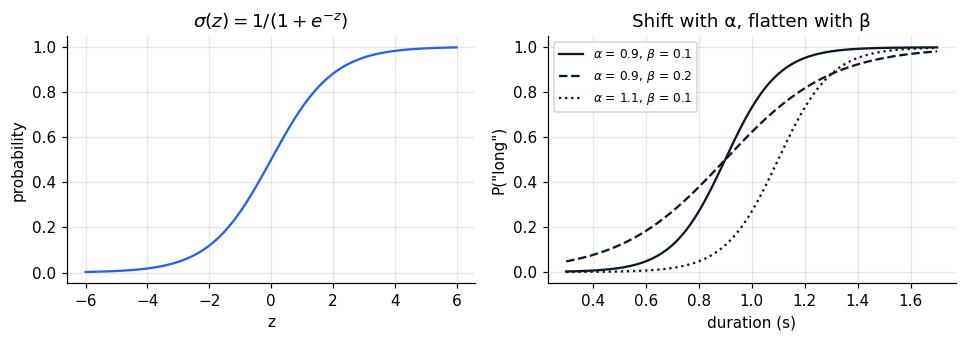

In [2]:
x = np.linspace(-6, 6, 300)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(x, expit(x), color="#2563eb")
axes[0].set(title=r"$\sigma(z) = 1/(1+e^{-z})$", xlabel="z", ylabel="probability")
d = np.linspace(0.3, 1.7, 300)
for a, b, ls in [(0.9, 0.10, "-"), (0.9, 0.20, "--"), (1.1, 0.10, ":")]:
    axes[1].plot(d, expit((d - a) / b), ls=ls, color="#0f172a",
                 label=fr"$\alpha$ = {a}, $\beta$ = {b}")
axes[1].set(title="Shift with α, flatten with β", xlabel="duration (s)", ylabel='P("long")')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## The likelihood, written out

Each trial is a coin flip whose probability of "long" is $p_i = \sigma((x_i-\alpha)/\beta)$. The
likelihood of all $n$ responses $y_i \in \{0, 1\}$ is a product of Bernoulli probabilities, and
its logarithm is

$$\log L(\alpha, \beta) = \sum_i \big[ y_i \log p_i + (1 - y_i) \log (1 - p_i) \big].$$

Maximising it is the same as minimising the **binary cross-entropy**, the loss used to train
neural network classifiers in notebook 6. We minimise the negative log-likelihood numerically,
optimising $\log\beta$ so the spread stays positive.

In [3]:
def nll(params, x, y, lapse=False):
    alpha, log_beta = params[:2]
    p = expit((x - alpha) / np.exp(log_beta))
    if lapse:
        lam = expit(params[2]) * 0.1          # lapse rate constrained to [0, 0.1]
        p = lam + (1 - 2 * lam) * p
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return -np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

def fit_psychometric(x, y, lapse=False):
    starts = [[np.median(x), np.log(0.1)] + ([-2.0] if lapse else [])]
    starts += [[a, np.log(b)] + ([-2.0] if lapse else []) for a in (0.7, 1.0, 1.3) for b in (0.05, 0.2)]
    best = min((minimize(nll, s, args=(x, y, lapse), method="Nelder-Mead") for s in starts),
               key=lambda r: r.fun)
    out = {"alpha": best.x[0], "beta": np.exp(best.x[1]), "nll": best.fun}
    if lapse:
        out["lapse"] = expit(best.x[2]) * 0.1
    return out

one = df.query("subject == 3 and spacing == 'dense-short'")
fit1 = fit_psychometric(one["duration"].to_numpy(), one["long"].to_numpy())
print({k: round(v, 4) for k, v in fit1.items()})

{'alpha': np.float64(0.8168), 'beta': np.float64(0.1672), 'nll': np.float64(132.4361)}


Running the optimiser from several starting points and keeping the best guards against local
minima. For a two-parameter logistic the likelihood is well behaved, but the habit pays off as
soon as lapse rates or more complex models enter.

## Checking against a library

A logistic regression in `statsmodels` maximises the same likelihood in the $(\beta_0, \beta_1)$
parameterisation. Converting gives the same $\alpha$ and $\beta$.

In [4]:
glm = smf.logit("long ~ duration", data=one).fit(disp=0)
b0, b1 = glm.params
print(f"statsmodels: alpha = {-b0 / b1:.4f}, beta = {1 / b1:.4f}, nll = {-glm.llf:.4f}")
print(f"by hand:     alpha = {fit1['alpha']:.4f}, beta = {fit1['beta']:.4f}, nll = {fit1['nll']:.4f}")

statsmodels: alpha = 0.8168, beta = 0.1672, nll = 132.4361
by hand:     alpha = 0.8168, beta = 0.1672, nll = 132.4361


## Lapses

Occasionally a participant presses the wrong key or blinks through a stimulus. A plain logistic
must then bend its tails to explain a "short" response to the longest duration, which flattens
the slope. A lapse parameter $\lambda$ lets the curve asymptote at $\lambda$ and $1-\lambda$
instead:

$$P(\text{"long"} \mid x) = \lambda + (1 - 2\lambda)\,\sigma\!\left(\frac{x - \alpha}{\beta}\right).$$

Fit both models to every participant and condition.

In [5]:
rows = []
for (s, sp), g in df.groupby(["subject", "spacing"]):
    xg, yg = g["duration"].to_numpy(), g["long"].to_numpy()
    plain, lapsed = fit_psychometric(xg, yg), fit_psychometric(xg, yg, lapse=True)
    rows.append({"subject": s, "spacing": sp,
                 "alpha": lapsed["alpha"], "beta": lapsed["beta"], "lapse": lapsed["lapse"],
                 "beta_plain": plain["beta"], "lr": 2 * (plain["nll"] - lapsed["nll"])})
fits = pd.DataFrame(rows)
print(fits.groupby("spacing")[["alpha", "beta", "beta_plain", "lapse"]].mean().round(3))
print(f"\nlapse model improves fit by > 3.84 (chi-square, 1 df) in "
      f"{(fits['lr'] > 3.84).sum()} of {len(fits)} fits")

             alpha   beta  beta_plain  lapse
spacing                                     
dense-long   0.935  0.114       0.122  0.004
dense-short  0.835  0.092       0.106  0.009

lapse model improves fit by > 3.84 (chi-square, 1 df) in 5 of 30 fits


Plot the fitted curves over the data for two participants. Participant 3 shows the typical
context effect; participant 9 is one of the two who show the reverse.

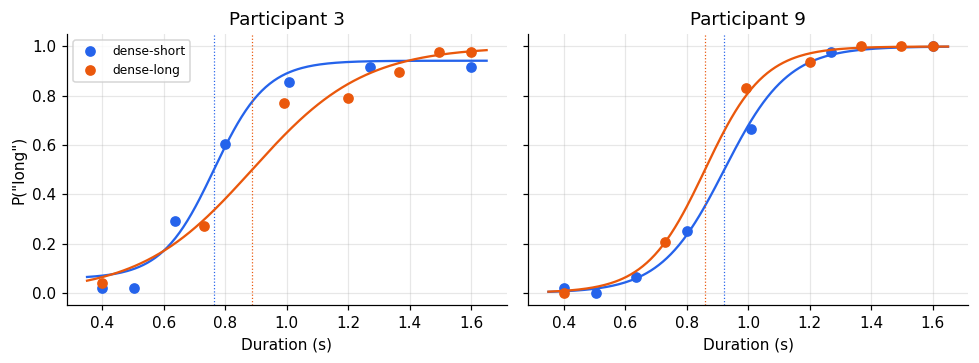

In [6]:
agg = df.groupby(["subject", "spacing", "duration"], as_index=False)["long"].mean()
xs = np.linspace(0.35, 1.65, 200)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, s in zip(axes, [3, 9]):
    for sp in colors:
        a = agg.query("subject == @s and spacing == @sp")
        f = fits.query("subject == @s and spacing == @sp").iloc[0]
        ax.plot(a["duration"], a["long"], "o", color=colors[sp], label=sp)
        p = f["lapse"] + (1 - 2 * f["lapse"]) * expit((xs - f["alpha"]) / f["beta"])
        ax.plot(xs, p, color=colors[sp])
        ax.axvline(f["alpha"], color=colors[sp], lw=0.8, ls=":")
    ax.set(title=f"Participant {s}", xlabel="Duration (s)")
axes[0].set_ylabel('P("long")')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Bisection point and Weber fraction

Two summary quantities matter for timing. The **bisection point** $\alpha$ is where "short" and
"long" are equally likely. The **Weber fraction** expresses sensitivity relative to the
magnitude being judged. With the logistic, the 25% and 75% points lie $\beta\ln 3$ either side of
$\alpha$, so the just-noticeable difference is $\mathrm{JND} = \beta\ln 3$ and
$\mathrm{WF} = \mathrm{JND}/\alpha$.

In [7]:
fits["wf"] = fits["beta"] * np.log(3) / fits["alpha"]
wide = fits.pivot(index="subject", columns="spacing", values=["alpha", "wf"])
print(wide.mean().unstack().round(3))
shift = wide["alpha"]["dense-long"] - wide["alpha"]["dense-short"]
print(f"\nBP shift (dense-long − dense-short): {shift.mean():.3f} s ± {shift.sem():.3f} SEM, "
      f"positive in {(shift > 0).sum()} of {len(shift)}")

spacing  dense-long  dense-short
alpha         0.935        0.835
wf            0.134        0.123

BP shift (dense-long − dense-short): 0.101 s ± 0.020 SEM, positive in 13 of 15


The fitted bisection points reproduce the context effect from notebook 1, now from all trials
rather than from two neighbouring points.

## One model for the whole group

Fitting each participant separately and then testing the parameters is the two-stage approach
from notebook 1. Alternatively, one logistic regression can include spacing as a predictor. On
the log-odds scale the spacing effect is a shift of the intercept, which is a shift of the
bisection point. Clustered standard errors by participant account for repeated measures, a
simple alternative to the mixed models of notebook 3.

In [8]:
group_fit = smf.logit("long ~ duration + C(spacing, Treatment('dense-short'))", data=df).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": df["subject"]})
print(group_fit.summary().tables[1])
b = group_fit.params
print(f"\nimplied BP: dense-short = {-b['Intercept'] / b['duration']:.3f} s, "
      f"dense-long = {-(b['Intercept'] + b.iloc[1]) / b['duration']:.3f} s")

                                                         coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
Intercept                                             -5.9397      0.450    -13.210      0.000      -6.821      -5.058
C(spacing, Treatment('dense-short'))[T.dense-long]    -0.6611      0.159     -4.161      0.000      -0.973      -0.350
duration                                               7.0416      0.457     15.411      0.000       6.146       7.937

implied BP: dense-short = 0.844 s, dense-long = 0.937 s


The pooled bisection points match the averages of the individual fits closely. The pooled
model does assume that every participant has the same slope, which the individual fits show is
not true.

## The same sigmoid is an artificial neuron

Strip away the psychophysics and the model is: take a weighted sum of inputs, add a bias, and
pass it through a nonlinearity. That is exactly the unit from which neural networks are built.
The nonlinearity is called the **activation function**, and the choice matters.

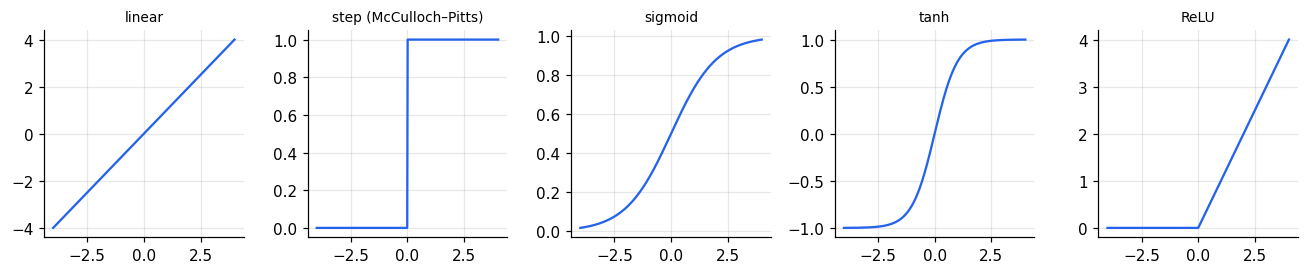

In [9]:
z = np.linspace(-4, 4, 400)
acts = {
    "linear": z,
    "step (McCulloch-Pitts)": (z > 0).astype(float),
    "sigmoid": expit(z),
    "tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
}
fig, axes = plt.subplots(1, 5, figsize=(12, 2.6), sharex=True)
for ax, (name, a) in zip(axes, acts.items()):
    ax.plot(z, a, color="#2563eb")
    ax.set_title(name, fontsize=9)
plt.tight_layout()
plt.show()

- **Linear**: stacking linear units gives another linear map, so depth adds nothing.
- **Step**: the McCulloch-Pitts threshold unit (notebook 5); not differentiable, so it cannot be
  trained by gradients.
- **Sigmoid**: a probability, as here. Its gradient vanishes in both tails, which slows learning
  in deep networks.
- **tanh**: a zero-centred sigmoid.
- **ReLU**: zero below threshold, linear above. Cheap, does not saturate for positive input, and
  the default in modern deep networks. It also resembles a neuron's firing-rate curve.

## Summary

- Logistic regression models the log-odds of a binary response as linear in the predictors.
- Reparameterised as $\sigma((x-\alpha)/\beta)$, it is a psychometric function with a 50% point
  and a spread.
- The negative log-likelihood is the binary cross-entropy; minimise it from several starting
  points.
- Lapse rates stop a few careless trials from flattening the slope.
- A logistic unit is an artificial neuron with a sigmoid activation.